In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string

from collections import Counter

# Load datasets
train_df = pd.read_csv("twitter_training.csv", header=None)
val_df = pd.read_csv("twitter_validation.csv", header=None)

# Add column names
train_df.columns = ["Tweet_ID", "Entity", "Sentiment", "Tweet"]
val_df.columns = ["Tweet_ID", "Entity", "Sentiment", "Tweet"]

print("Training Dataset Shape:", train_df.shape)
print("Validation Dataset Shape:", val_df.shape)

Training Dataset Shape: (74682, 4)
Validation Dataset Shape: (1000, 4)


In [5]:
train_df.head()

,Tweet_ID,Entity,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [6]:
val_df.head()

,Tweet_ID,Entity,Sentiment,Tweet
0,3364,Facebook,Irrelevant,I mentioned on Facebook that I was struggling ...
1,352,Amazon,Neutral,BBC News - Amazon boss Jeff Bezos rejects clai...
2,8312,Microsoft,Negative,@Microsoft Why do I pay for WORD when it funct...
3,4371,CS-GO,Negative,"CSGO matchmaking is so full of closet hacking,..."
4,4433,Google,Neutral,Now the President is slapping Americans in the...


In [7]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Tweet_ID   74682 non-null  int64 
 1   Entity     74682 non-null  object
 2   Sentiment  74682 non-null  object
 3   Tweet      73996 non-null  object
dtypes: int64(1), object(3)
memory usage: 2.3+ MB


In [8]:
train_df.describe(include="all")

,Tweet_ID,Entity,Sentiment,Tweet
count,74682.000000,74682,74682,73996
unique,NaN,32,4,69491
top,NaN,Microsoft,Negative,
freq,NaN,2400,22542,172
mean,6432.586165,NaN,NaN,NaN
std,3740.427870,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN
25%,3195.000000,NaN,NaN,NaN
50%,6422.000000,NaN,NaN,NaN
75%,9601.000000,NaN,NaN,NaN


In [9]:
train_df["Sentiment"].value_counts()

Sentiment
Negative      22542
Positive      20832
Neutral       18318
Irrelevant    12990
Name: count, dtype: int64

In [10]:
train_df["Entity"].nunique()

32

In [11]:
train_df["Entity"].value_counts().head(10)

Entity
Microsoft                    2400
MaddenNFL                    2400
TomClancysRainbowSix         2400
LeagueOfLegends              2394
CallOfDuty                   2394
Verizon                      2382
CallOfDutyBlackopsColdWar    2376
ApexLegends                  2376
Facebook                     2370
WorldOfCraft                 2364
Name: count, dtype: int64

In [12]:
train_df.isnull().sum()

Tweet_ID       0
Entity         0
Sentiment      0
Tweet        686
dtype: int64

In [13]:
train_df = train_df.dropna(subset=["Tweet"]).copy()

In [14]:
train_df.isnull().sum()

Tweet_ID     0
Entity       0
Sentiment    0
Tweet        0
dtype: int64

In [15]:
print("Duplicate rows:", train_df.duplicated().sum())

Duplicate rows: 2340


In [16]:
train_df = train_df.drop_duplicates().copy()

In [17]:
print("Dataset shape after cleaning:", train_df.shape)

Dataset shape after cleaning: (71656, 4)


In [18]:
sentiment_counts = train_df["Sentiment"].value_counts()

print(sentiment_counts)

Sentiment
Negative      21698
Positive      19713
Neutral       17708
Irrelevant    12537
Name: count, dtype: int64


In [19]:
sentiment_percentage = (
    train_df["Sentiment"]
    .value_counts(normalize=True) * 100
)

print(sentiment_percentage.round(2))

Sentiment
Negative      30.28
Positive      27.51
Neutral       24.71
Irrelevant    17.50
Name: proportion, dtype: float64


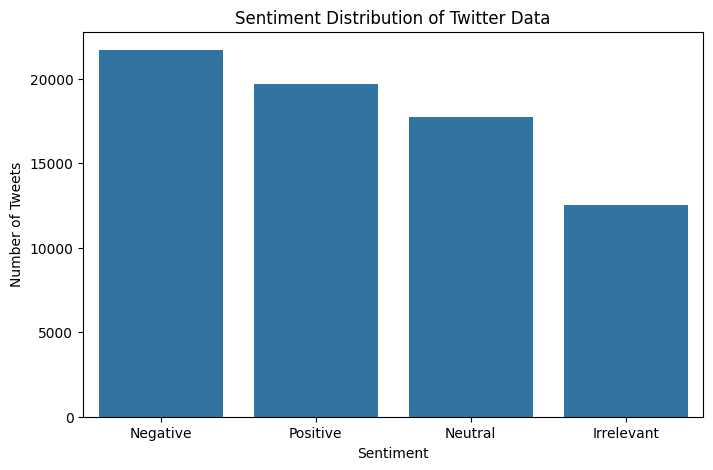

In [20]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=train_df,
    x="Sentiment",
    order=train_df["Sentiment"].value_counts().index
)

plt.title("Sentiment Distribution of Twitter Data")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.show()

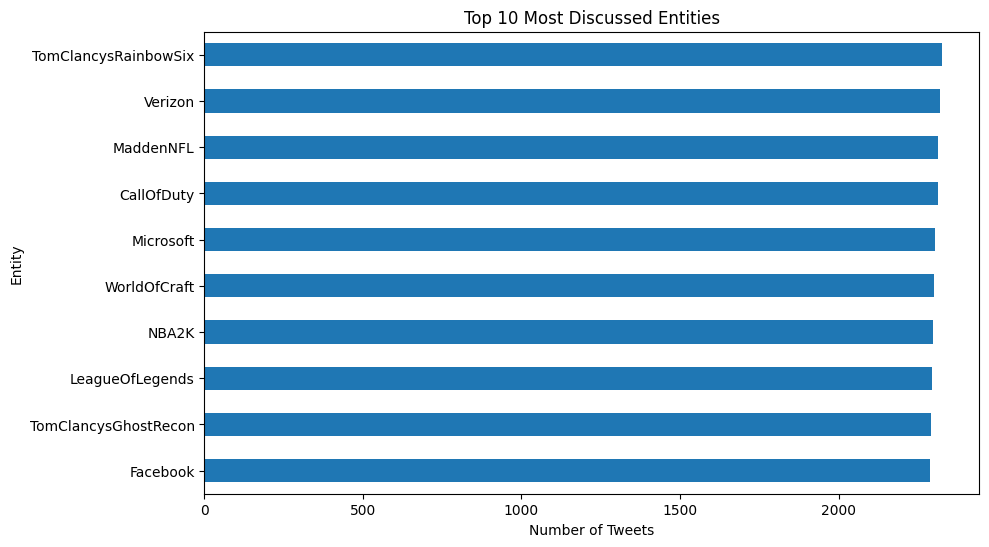

In [21]:
top_entities = train_df["Entity"].value_counts().head(10)

plt.figure(figsize=(10,6))

top_entities.sort_values().plot(kind="barh")

plt.title("Top 10 Most Discussed Entities")
plt.xlabel("Number of Tweets")
plt.ylabel("Entity")

plt.show()

In [22]:
top_10 = train_df["Entity"].value_counts().head(10).index

entity_sentiment = pd.crosstab(
    train_df[train_df["Entity"].isin(top_10)]["Entity"],
    train_df[train_df["Entity"].isin(top_10)]["Sentiment"]
)

entity_sentiment

Sentiment,Irrelevant,Negative,Neutral,Positive
Entity,,,,
CallOfDuty,660,861,367,426
Facebook,672,690,773,154
LeagueOfLegends,298,616,800,582
MaddenNFL,86,1665,191,373
Microsoft,167,748,816,573
NBA2K,175,1450,265,409
TomClancysGhostRecon,23,887,776,605
TomClancysRainbowSix,92,1110,628,498
Verizon,177,1070,552,520


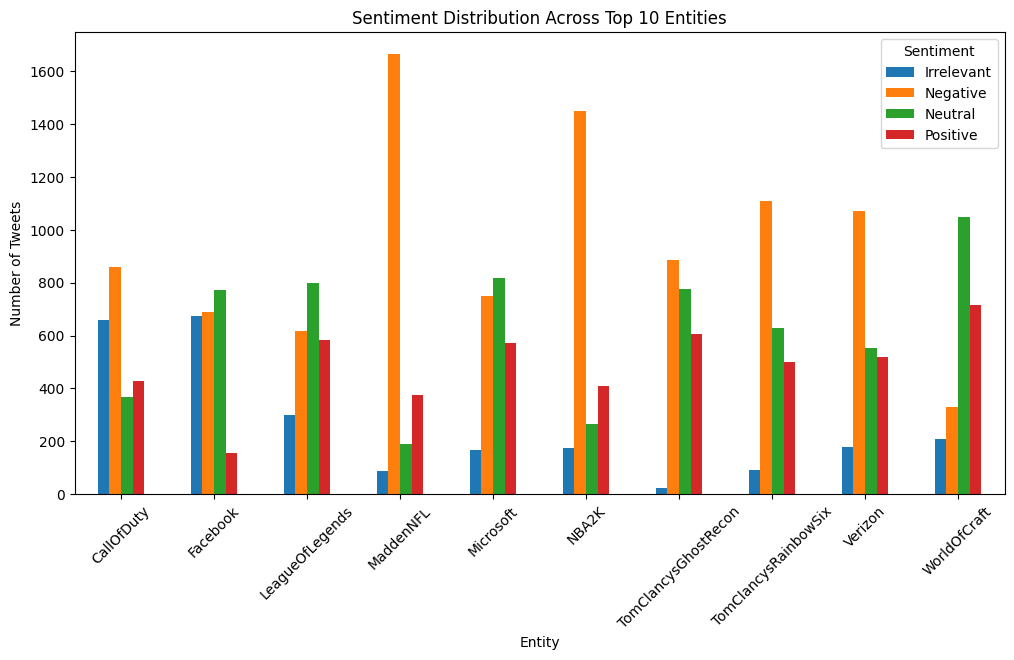

In [23]:
entity_sentiment.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Sentiment Distribution Across Top 10 Entities")
plt.xlabel("Entity")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)

plt.legend(title="Sentiment")
plt.show()

In [24]:
def clean_text(text):
    text = str(text).lower()
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    
    # Remove mentions
    text = re.sub(r"@\w+", "", text)
    
    # Remove hashtag symbol
    text = re.sub(r"#", "", text)
    
    # Remove punctuation
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

In [25]:
train_df["Clean_Tweet"] = train_df["Tweet"].apply(clean_text)

In [26]:
train_df[["Tweet", "Clean_Tweet"]].head(10)

,Tweet,Clean_Tweet
0,im getting on borderlands and i will murder yo...,im getting on borderlands and i will murder yo...
1,I am coming to the borders and I will kill you...,i am coming to the borders and i will kill you...
2,im getting on borderlands and i will kill you ...,im getting on borderlands and i will kill you all
3,im coming on borderlands and i will murder you...,im coming on borderlands and i will murder you...
4,im getting on borderlands 2 and i will murder ...,im getting on borderlands 2 and i will murder ...
5,im getting into borderlands and i can murder y...,im getting into borderlands and i can murder y...
6,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...
7,So I spent a couple of hours doing something f...,so i spent a couple of hours doing something f...
8,So I spent a few hours doing something for fun...,so i spent a few hours doing something for fun...
9,So I spent a few hours making something for fu...,so i spent a few hours making something for fu...


In [27]:
all_words = " ".join(train_df["Clean_Tweet"])

words = all_words.split()

word_counts = Counter(words)

common_words = word_counts.most_common(20)

common_words

[('the', 43875),
 ('i', 28584),
 ('to', 28446),
 ('and', 26279),
 ('a', 23822),
 ('of', 19149),
 ('is', 17479),
 ('for', 15404),
 ('in', 15177),
 ('this', 14327),
 ('it', 13583),
 ('you', 11986),
 ('on', 11866),
 ('my', 11623),
 ('that', 10107),
 ('with', 8742),
 ('game', 7958),
 ('so', 7618),
 ('me', 6832),
 ('have', 6612)]

In [28]:
common_words_df = pd.DataFrame(
    common_words,
    columns=["Word", "Frequency"]
)

common_words_df

,Word,Frequency
0,the,43875
1,i,28584
2,to,28446
3,and,26279
4,a,23822
5,of,19149
6,is,17479
7,for,15404
8,in,15177
9,this,14327


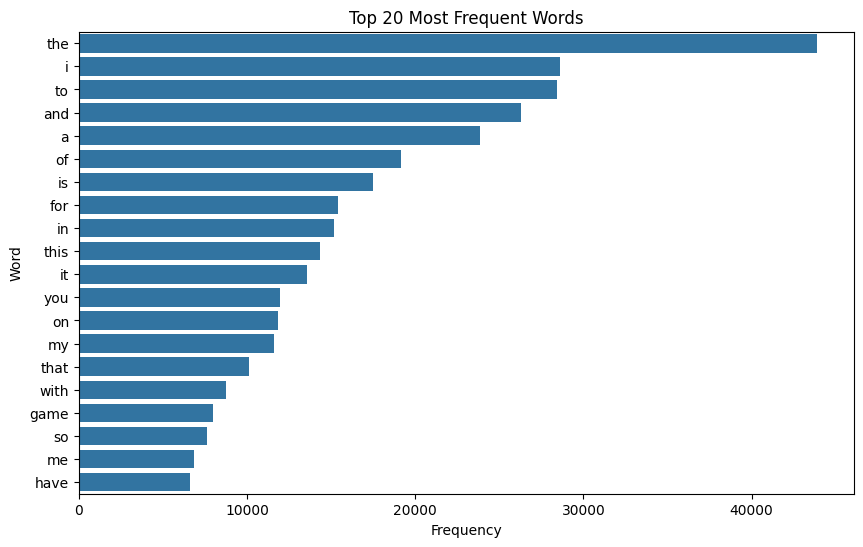

In [29]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=common_words_df,
    x="Frequency",
    y="Word"
)

plt.title("Top 20 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.show()

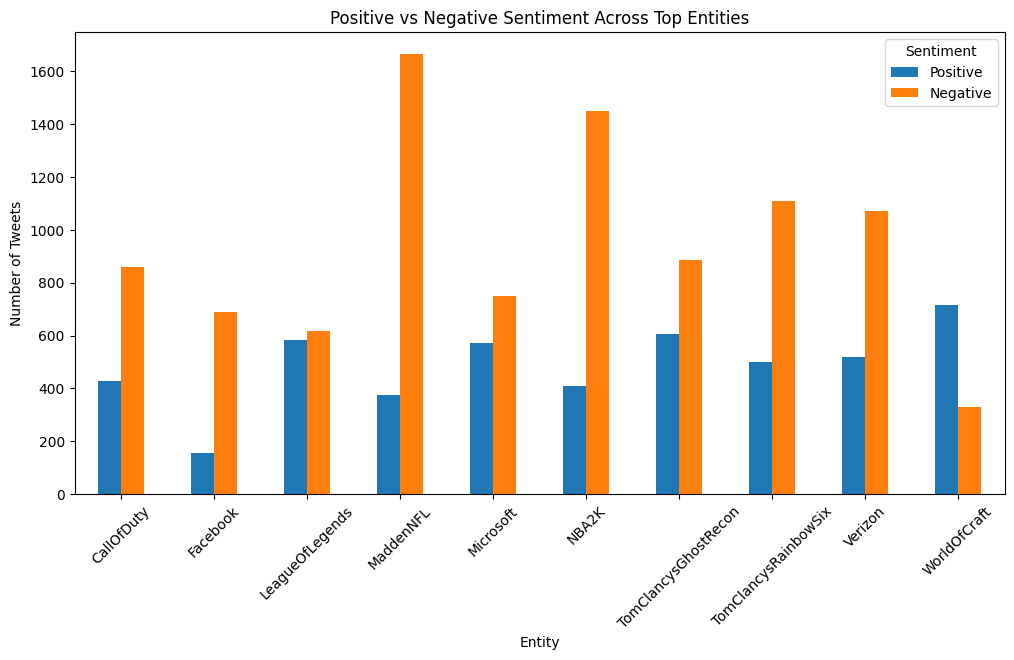

In [32]:
# Positive vs Negative Sentiment Across Top Entities

comparison = entity_sentiment[["Positive", "Negative"]]

comparison.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Positive vs Negative Sentiment Across Top Entities")
plt.xlabel("Entity")
plt.ylabel("Number of Tweets")
plt.xticks(rotation=45)

plt.legend(title="Sentiment")
plt.show()

## Conclusion

The sentiment analysis of Twitter data helped identify public opinions and attitudes toward different entities and topics. The analysis showed that negative sentiment was the most common sentiment category in the dataset, followed by positive and neutral sentiments. Entity-wise analysis helped compare positive and negative public reactions toward different topics and brands. The frequent-word analysis also provided insights into commonly used terms in the tweets. Overall, the visualizations successfully revealed important sentiment patterns and helped understand public opinion in the social media dataset.